In [12]:
import numpy as np
import matplotlib.pyplot as plt

import os
from statsmodels.stats.weightstats import DescrStatsW

import numpy as np
import scipy.stats as stats

import MDAnalysis as mda

In [ ]:
#                           GET RESIDUE INFORMATION FOR PYMOL INSPECTION

def residues(whichprotein, whichresidue):

    if whichprotein == "aac1":
        offset = 1
    elif whichprotein == "ucp1":
        offset = 9
    else:
        print(f"invalid protein {whichprotein}")
        return 0

    toppath = f"/home/jonathan/Documents/grabelab/rutter-lab-collaboration/test_trj/{whichprotein}/input/topol.top"
    trjpath = f"/home/jonathan/Documents/grabelab/rutter-lab-collaboration/test_trj/{whichprotein}/traj_comp.part0001-centered.xtc"
    u = mda.Universe(toppath, trjpath, topology_format='ITP')

    n_frames = len(u.trajectory)
    n_residues = len(u.select_atoms(f"resname {whichresidue.upper()}").residues)

    #print(u.select_atoms(f"resname {whichresidue.upper()}").residues)
    resseqs = [r.resid for r in u.select_atoms(f"resname {whichresidue.upper()}").residues]

    return resseqs

#residues("ucp1", "thr")

In [53]:
#                           BOOTSTRAPPING VS t-TEST MATH EXAMPLE
# bootstrapping yields smaller 95% CIs than the t test
# for our small sample sizes bootstrapping may actually be worse than a t test:  Am Stat. 2015 Dec 29;69(4):371–386. doi: 10.1080/00031305.2015.1089789 

print("                            bimodal")

# Consider the example of 10 data points at x=-0.1 and 10 data points at x=-1.1: 
data = [-0.1,-0.1,-0.1,-0.1,-0.1,-0.1,-0.1,-0.1,-0.1,-0.1,
        -1.1,-1.1,-1.1,-1.1,-1.1,-1.1,-1.1,-1.1,-1.1,-1.1]

confidence_level = 0.95

# Drawing bootstrap samples and computing the mean will always yield values in the range [-1.1,-0.1], so the 95% CI will not contain 0.
bootstrap_result = stats.bootstrap(data=(data,), statistic=np.mean, n_resamples=9999, confidence_level=confidence_level)
print(f"thought experiment bootstrap {confidence_level*100}% confidence interval: ({bootstrap_result.confidence_interval.low}, {bootstrap_result.confidence_interval.high})")
print(f"thought experiment bootstrap {confidence_level*100}% confidence interval width = {bootstrap_result.confidence_interval.high-bootstrap_result.confidence_interval.low}")

# A t-test yields
ci = stats.t.interval(confidence_level, df=len(data)-1, loc=np.mean(data), scale=np.std(data, ddof=1) / np.sqrt(len(data)))
print(f"thought experiment t test {confidence_level*100}% confidence interval: {ci}")
print(f"thought experiment t test {confidence_level*100}% confidence interval width: {ci[1]-ci[0]}")

print("                            bimodal with more data")

# Consider the example of 10 data points at x=-0.1 and 10 data points at x=-1.1: 
data = list(np.ones(100)*-0.1)+list(np.ones(100)*-1.1)

confidence_level = 0.95

# Drawing bootstrap samples and computing the mean will always yield values in the range [-1.1,-0.1], so the 95% CI will not contain 0.
bootstrap_result = stats.bootstrap(data=(data,), statistic=np.mean, n_resamples=9999, confidence_level=confidence_level)
print(f"thought experiment bootstrap {confidence_level*100}% confidence interval: ({bootstrap_result.confidence_interval.low}, {bootstrap_result.confidence_interval.high})")
print(f"thought experiment bootstrap {confidence_level*100}% confidence interval width = {bootstrap_result.confidence_interval.high-bootstrap_result.confidence_interval.low}")

# A t-test yields
ci = stats.t.interval(confidence_level, df=len(data)-1, loc=np.mean(data), scale=np.std(data, ddof=1) / np.sqrt(len(data)))
print(f"thought experiment t test {confidence_level*100}% confidence interval: {ci}")
print(f"thought experiment t test {confidence_level*100}% confidence interval width: {ci[1]-ci[0]}")

print("                            unimodal")

# If instead the data are unimodally distributed:
data = [-0.1,-0.2,-0.3,-0.3,-0.4,-0.4,-0.4,-0.5,-0.5,-0.5,
        -0.5,-0.5,-0.5,-0.6,-0.6,-0.7,-0.8,-0.9,-1.0,-1.1]

confidence_level = 0.95

# Drawing bootstrap samples and computing the mean will always yield values in the range [-1.1,-0.1], so the 95% CI will not contain 0.
bootstrap_result = stats.bootstrap(data=(data,), statistic=np.mean, n_resamples=9999, confidence_level=confidence_level)
print(f"thought experiment bootstrap {confidence_level*100}% confidence interval: ({bootstrap_result.confidence_interval.low}, {bootstrap_result.confidence_interval.high})")
print(f"thought experiment bootstrap {confidence_level*100}% confidence interval width = {bootstrap_result.confidence_interval.high-bootstrap_result.confidence_interval.low}")

# A t-test yields
ci = stats.t.interval(confidence_level, df=len(data)-1, loc=np.mean(data), scale=np.std(data, ddof=1) / np.sqrt(len(data)))
print(f"thought experiment t test {confidence_level*100}% confidence interval: {ci}")
print(f"thought experiment t test {confidence_level*100}% confidence interval width: {ci[1]-ci[0]}")

print("                            unimodal with outliers")

# If instead the data are unimodally distributed:
data = [1,0.5,-0.3,-0.3,-0.4,-0.4,-0.4,-0.5,-0.5,-0.5,
        -0.5,-0.5,-0.5,-0.6,-0.6,-0.7,-0.8,-0.9,-1.6,-2]

confidence_level = 0.95

# Drawing bootstrap samples and computing the mean will always yield values in the range [-1.1,-0.1], so the 95% CI will not contain 0.
bootstrap_result = stats.bootstrap(data=(data,), statistic=np.mean, n_resamples=9999, confidence_level=confidence_level)
print(f"thought experiment bootstrap {confidence_level*100}% confidence interval: ({bootstrap_result.confidence_interval.low}, {bootstrap_result.confidence_interval.high})")
print(f"thought experiment bootstrap {confidence_level*100}% confidence interval width = {bootstrap_result.confidence_interval.high-bootstrap_result.confidence_interval.low}")

# A t-test yields
ci = stats.t.interval(confidence_level, df=len(data)-1, loc=np.mean(data), scale=np.std(data, ddof=1) / np.sqrt(len(data)))
print(f"thought experiment t test {confidence_level*100}% confidence interval: {ci}")
print(f"thought experiment t test {confidence_level*100}% confidence interval width: {ci[1]-ci[0]}")

print("                            unimodal skewed")

# If instead the data are unimodally distributed:
data = [3,2,1.2,1,0.5,-0.4,-0.4,-0.5,-0.5,-0.5,
        -0.5,-0.5,-0.5,-0.6,-0.6,-0.7,-0.8,-0.9]

confidence_level = 0.95

# Drawing bootstrap samples and computing the mean will always yield values in the range [-1.1,-0.1], so the 95% CI will not contain 0.
bootstrap_result = stats.bootstrap(data=(data,), statistic=np.mean, n_resamples=9999, confidence_level=confidence_level)
print(f"thought experiment bootstrap {confidence_level*100}% confidence interval: ({bootstrap_result.confidence_interval.low}, {bootstrap_result.confidence_interval.high})")
print(f"thought experiment bootstrap {confidence_level*100}% confidence interval width = {bootstrap_result.confidence_interval.high-bootstrap_result.confidence_interval.low}")

# A t-test yields
ci = stats.t.interval(confidence_level, df=len(data)-1, loc=np.mean(data), scale=np.std(data, ddof=1) / np.sqrt(len(data)))
print(f"thought experiment t test {confidence_level*100}% confidence interval: {ci}")
print(f"thought experiment t test {confidence_level*100}% confidence interval width: {ci[1]-ci[0]}")

#the following says the same:
#https://medium.com/data-science/bootstrap-statistics-how-to-work-around-limitations-of-simple-statistical-tests-13180a301efd

                            bimodal
thought experiment bootstrap 95.0% confidence interval: (-0.8, -0.4)
thought experiment bootstrap 95.0% confidence interval width = 0.4
thought experiment t test 95.0% confidence interval: (-0.8400863247254051, -0.3599136752745949)
thought experiment t test 95.0% confidence interval width: 0.48017264945081023
                            bimodal with more data
thought experiment bootstrap 95.0% confidence interval: (-0.6699999999999998, -0.5299999999999999)
thought experiment bootstrap 95.0% confidence interval width = 0.1399999999999999
thought experiment t test 95.0% confidence interval: (-0.6698941465655791, -0.5301058534344206)
thought experiment t test 95.0% confidence interval width: 0.13978829313115848
                            unimodal
thought experiment bootstrap 95.0% confidence interval: (-0.6599999999999999, -0.43999999999999995)
thought experiment bootstrap 95.0% confidence interval width = 0.21999999999999997
thought experiment t test 

In [ ]:
#Question:
#Does solvation (hydrogen bonding with water) shift the rotamer distribution of threonines on helices?

def heatmap_1(rotamer_data, hbond_data, helix_data, framerates, resseqs):

    #change in delta-g of adopting the 180 degree rotamer between wet and dry conditions
    ddG_all = []
    #length of simulation for which residue is on a helix
    weights_all = [] 

    resseqs_out = []

    for nr in range(rotamer_data.shape[0]):

        helix_rotamer_hbonds = np.zeros((2,3,3))

        for x,y,z,f in zip(helix_data[nr], rotamer_data[nr], hbond_data[nr], framerates):
            helix_rotamer_hbonds[x,y,z]+=1/f

        r_hb = np.array([[helix_rotamer_hbonds[1,0,0],           np.sum(helix_rotamer_hbonds[1,0,1:3])],
                         [np.sum(helix_rotamer_hbonds[1,1:3,0]), np.sum(helix_rotamer_hbonds[1,1:3,1:3])]])

        plot_mat = False
        if plot_mat:
            print(helix_rotamer_hbonds[1])
            plt.imshow(helix_rotamer_hbonds[1])
            plt.ylabel("rotamer")
            plt.xlabel("number of hydrogen bonds")
            plt.yticks([0,1,2],[180, -60, 60])
            plt.xticks([0,1,2],[0,1,2])
            plt.show()
        #print(np.sum(helix_rotamer_hbonds)/5000)

        #calculate effect of hydrogen bonding with water on rotamer free energy
        #we can't do this calculation unless we have sampled in all four states
        if np.all(r_hb>0): 

            dG_rot_dry = -np.log(r_hb[0,0]/r_hb[1,0])
            dG_rot_wet = -np.log(r_hb[0,1]/r_hb[1,1])

            ddG_all.append(dG_rot_wet-dG_rot_dry)
            weights_all.append(np.sum(r_hb))
            #print(np.sum(r_hb)/5000)
            resseqs_out.append(resseqs[nr])

            plot_mat_2 = False
            if plot_mat_2:
                print(helix_rotamer_hbonds[1])
                plt.imshow(helix_rotamer_hbonds[1])
                plt.ylabel("rotamer")
                plt.xlabel("number of hydrogen bonds")
                plt.yticks([0,1,2],[180, -60, 60])
                plt.xticks([0,1,2],[0,1,2])
                plt.show()

        else:
            print(str(resseqs[nr]) + " not sampled in all 4 states")
    # plt.hist(dg_all, weights = weights_all, bins=20, range = (-5,5), density = True)
    # plt.show()
    print(f"raw delta-delta-G values: {ddG_all}")

    confidence_level = 0.95
    # we don't know if the set of delta G values from all relevant protein chemical environments is t-distributed
    # and there is not really any good reason to expect it to be in general
    ci = stats.t.interval(confidence_level, df=len(ddG_all)-1, loc=np.mean(ddG_all), scale=np.std(ddG_all, ddof=1) / np.sqrt(len(ddG_all)))
    print(f"single-protein {confidence_level*100}% t test confidence interval: {ci}")

    bootstrap_result = stats.bootstrap(data=(ddG_all,), statistic=np.mean, n_resamples=9999, confidence_level=confidence_level)
    print(f"single-protein {confidence_level*100}% bootstrap confidence interval: ({bootstrap_result.confidence_interval.low}, {bootstrap_result.confidence_interval.high})")

    #MG meeting list
    #TODO-N/A; also get a spearman CI - this does not appear to be the right test for this purpose
    #TODO-done: try bootstrapping - this yields smaller 95% CIs than the t test
    # for our small sample sizes this may actually be worse:  Am Stat. 2015 Dec 29;69(4):371–386. doi: 10.1080/00031305.2015.1089789 
    # consider the example of 10 data points at x=-0.1 and 10 data points at x=-1.1. 
    #   Drawing bootstrap samples and computing the mean will always yield values in the range [-1.1,-0.1], so the 95% CI will not contain 0.
    #   However computing the standard deviation 
    #TODO-done and then overdone: try giving each site a fixed solvation assignment and then testing the 
    # difference of means between the deltaG +-60/180 for solvated and non-solvated ones 
    #TODO-done write code to print the protein and pdb index to facilitate residue inspection
    #   this reveals no discernable pattern (i.e. the highest and lowest delta-delta-G of the 180 degree rotamer upon solvation 
    #   are not concentrated in any particular solvation state or spatial area). Anecdotally ddG of membrane-facing residues had less dispersion
    #TODO-cancelled given the results of the above: calculate delta G value based on hbond frac in "solvated" helices and non-solvated ones 
    # to get actual rotamer delta-G for membrane and water helices given the imperfect correspondence between solvent and hydrogen bond formation
    # see formula in fixed solvation notebook
    #TODO-done - look at transitions: everything has at least a few rotamer transitions each way even in one short segment so nothing is so kinetically trapped
    # that it needs to be thrown out
    
    return ddG_all, weights_all, resseqs_out


In [67]:
def load_process(analysis_method, resn):

    #this path actually also contains serine rotamers
    inputpath = "/home/jonathan/Documents/grabelab/rutter-lab-collaboration/thr_rotamers_solvation/resi_data"

    servers = ["wynton", "degrabo"]
    proteins = ["ucp1", "aac1"]

    weights_all = []
    ddG_all = []
    prot_all = []
    resseq_all = []

    #loop over servers, proteins, and parallel runs
    for protein in proteins:

        resseqs = residues(protein, resn)

        print("---------------------------------------------: " +protein)
        rotamer_data = []
        hbond_data = []
        helix_data = []
        framerates = []

        for server in servers:    
            for run in range(1,5):
                #not all servers have the same number of parallel simulations
                if run > 2 and server == "degrabo": continue

                if run > 2:
                    framerate = 2
                else:
                    framerate = 1

                for seg in range(1,20):
                    #load data if it exists
                    rotamer_file = f"{inputpath}/{server}/{protein}/run0{run}/{protein}-{server}-run0{run}-seg{str(seg).zfill(2)}-{resn}-rotamers.npy"
                    hbond_file = f"{inputpath}/{server}/{protein}/run0{run}/{protein}-{server}-run0{run}-seg{str(seg).zfill(2)}-{resn}-hbonds.npy"
                    secstr_file = f"{inputpath}/{server}/{protein}/run0{run}/{protein}-{server}-run0{run}-seg{str(seg).zfill(2)}-{resn}-secstr.npy"

                    if os.path.exists(rotamer_file) and os.path.exists(hbond_file) and os.path.exists(secstr_file):
                        rotamer_data.append(np.load(rotamer_file))
                        hbond_data.append(np.load(hbond_file))
                        helix_data.append(np.load(secstr_file))
                        framerates.append(framerate*np.ones(rotamer_data[-1].shape[1]))


        rotamer_data = np.concatenate(rotamer_data, axis = 1)
        hbond_data = np.concatenate(hbond_data, axis = 1)
        helix_data = np.concatenate(helix_data, axis = 1)
        framerates = np.concatenate(framerates, axis = 0)


        ddG, weights, resseqs = analysis_method(rotamer_data, hbond_data, helix_data, framerates, resseqs)
        ddG_all.append(ddG)
        weights_all.append(weights)

        resseq_all += resseqs
        prot_all += [protein for x in range(len(resseqs))]

    ddG_all = np.concatenate(ddG_all)
    weights_all = np.concatenate(weights_all)

    return ddG_all, weights_all, prot_all, resseq_all


In [81]:
    
def compile_results(ddG_all, weights_all, prot_all, resseq_all, resn):

    plot_with_alldata = True
    if plot_with_alldata:
        plt.show()

        plt.figure(figsize=(10,10), dpi=600)
        plt.scatter(weights_all, ddG_all)
        print(len(ddG_all))
        print(len(resseq_all))
        for p, r, w, g in zip(prot_all, resseq_all, weights_all, ddG_all):
            plt.annotate(f"{p}-{r}", (w, g+0.05), fontsize=6)

        helicity_thresh = 100000
        plt.axvline(helicity_thresh)

        plt.show()

        print("ucp1 helical resis:")
        print("+".join([str(r) for r, w, p in zip(resseq_all, weights_all, prot_all) if w>=helicity_thresh and p == "ucp1"]))
        print("aac1 helical resis:")
        print("+".join([str(r) for r, w, p in zip(resseq_all, weights_all, prot_all) if w>=helicity_thresh and p == "aac1"]))

        plt.hist(ddG_all, weights = weights_all, bins=20, range = (-5,5), density = True)

        confidence_level = 0.99
        # ci = stats.t.interval(confidence_level, df=len(dg_all)-1, loc=np.mean(dg_all), scale=np.std(dg_all, ddof=1) / np.sqrt(len(dg_all)))
        # print(f"{confidence_level*100}% confidence interval: {ci}")
        bootstrap_result = stats.bootstrap(data=(ddG_all,), statistic=np.mean, n_resamples=9999, confidence_level=confidence_level)
        print(f"single-protein {confidence_level*100}% confidence interval: {bootstrap_result.confidence_interval}")

    ddG_mostlyhelical = []
    weights_mostlyhelical = []

    #print(weights_all)

    for d, w in zip(ddG_all, weights_all):
        if w >= max(weights_all)*1/2:
            ddG_mostlyhelical.append(d)
            weights_mostlyhelical.append(w)

    print("---------------------------------------------: overall")
    
    print(f"data for {len(ddG_mostlyhelical)} residues")
    print(f"each residue used below has at least {min(weights_mostlyhelical)/5000} microseconds of aggregate data in a helix")
    print(f"water H-bonding favors 180 degree rotamer by {-np.mean(ddG_mostlyhelical):.2f} kT on helices")

    printrange=False
    if printrange:
        print(min(ddG_mostlyhelical))
        print(max(ddG_mostlyhelical))

    plt.show()
    plt.hist(ddG_mostlyhelical, bins=14, range = (-3.5,3.5), density = True)
    plt.xlim(-3.5,3.5)
    plt.ylim(0,0.5)
    plt.xlabel("free energy change of 180 degree\nrotamer upon water H-bonding (kT)")
    plt.ylabel("probability density")
    plt.savefig(f"figures/{resn}-rotamer-free-energy.png", bbox_inches="tight", dpi=600)

    confidence_level = 0.95
    ci = stats.t.interval(confidence_level, df=len(ddG_mostlyhelical)-1, loc=np.mean(ddG_mostlyhelical), scale=np.std(ddG_mostlyhelical, ddof=1) / np.sqrt(len(ddG_mostlyhelical)))
    print(f"2-protein combined {confidence_level*100}% t-test confidence interval: {ci}")
    bootstrap_result = stats.bootstrap(data=(ddG_all,), statistic=np.mean, n_resamples=9999, confidence_level=confidence_level)
    print(f"2-protein combined {confidence_level*100}% bootstrap confidence interval: ({bootstrap_result.confidence_interval.low}, {bootstrap_result.confidence_interval.high})")


In [82]:
#compile_results(ddG_all, weights_all, prot_all, resseq_all, resn)

/home/jonathan/anaconda3/envs/serpents/lib/python3.11/site-packages/MDAnalysis/topology/ITPParser.py:646: DeprecationWarning: The elements attribute has been populated by guessing elements from atom types. This behaviour has been temporarily added to the ITPParser as we transition to the new guessing API. This behavior will be removed in release 3.0. Please see issue #4698 for more information. 
  warnings.warn(


---------------------------------------------: ucp1
11 not sampled in all 4 states
30 not sampled in all 4 states
48 not sampled in all 4 states
154 not sampled in all 4 states
156 not sampled in all 4 states
177 not sampled in all 4 states
raw delta-delta-G values: [-3.1641713445490147, -1.8681396132618273, -1.4140123881446232, -0.28137064799991407, -0.7002156310382674, 0.18131874001650727, -0.10536051565782635, -0.6029214791376152, -1.8759343560760708, 1.792574396131437, -0.4315230781134711, -1.2882316077557086, -0.4285865170823935, -4.424463324871138, -2.342533874736934, -1.3752015207543398, -0.2970222689873614, 0.6635120334435616, -0.77872922701212, 0.7851217262410932]
single-protein 95.0% t test confidence interval: (-1.558143983889316, -0.2374450660452866)
single-protein 95.0% bootstrap confidence interval: (-1.5568265815601599, -0.3571181857603776)
---------------------------------------------: aac1
125 not sampled in all 4 states
154 not sampled in all 4 states
218 not sampled 

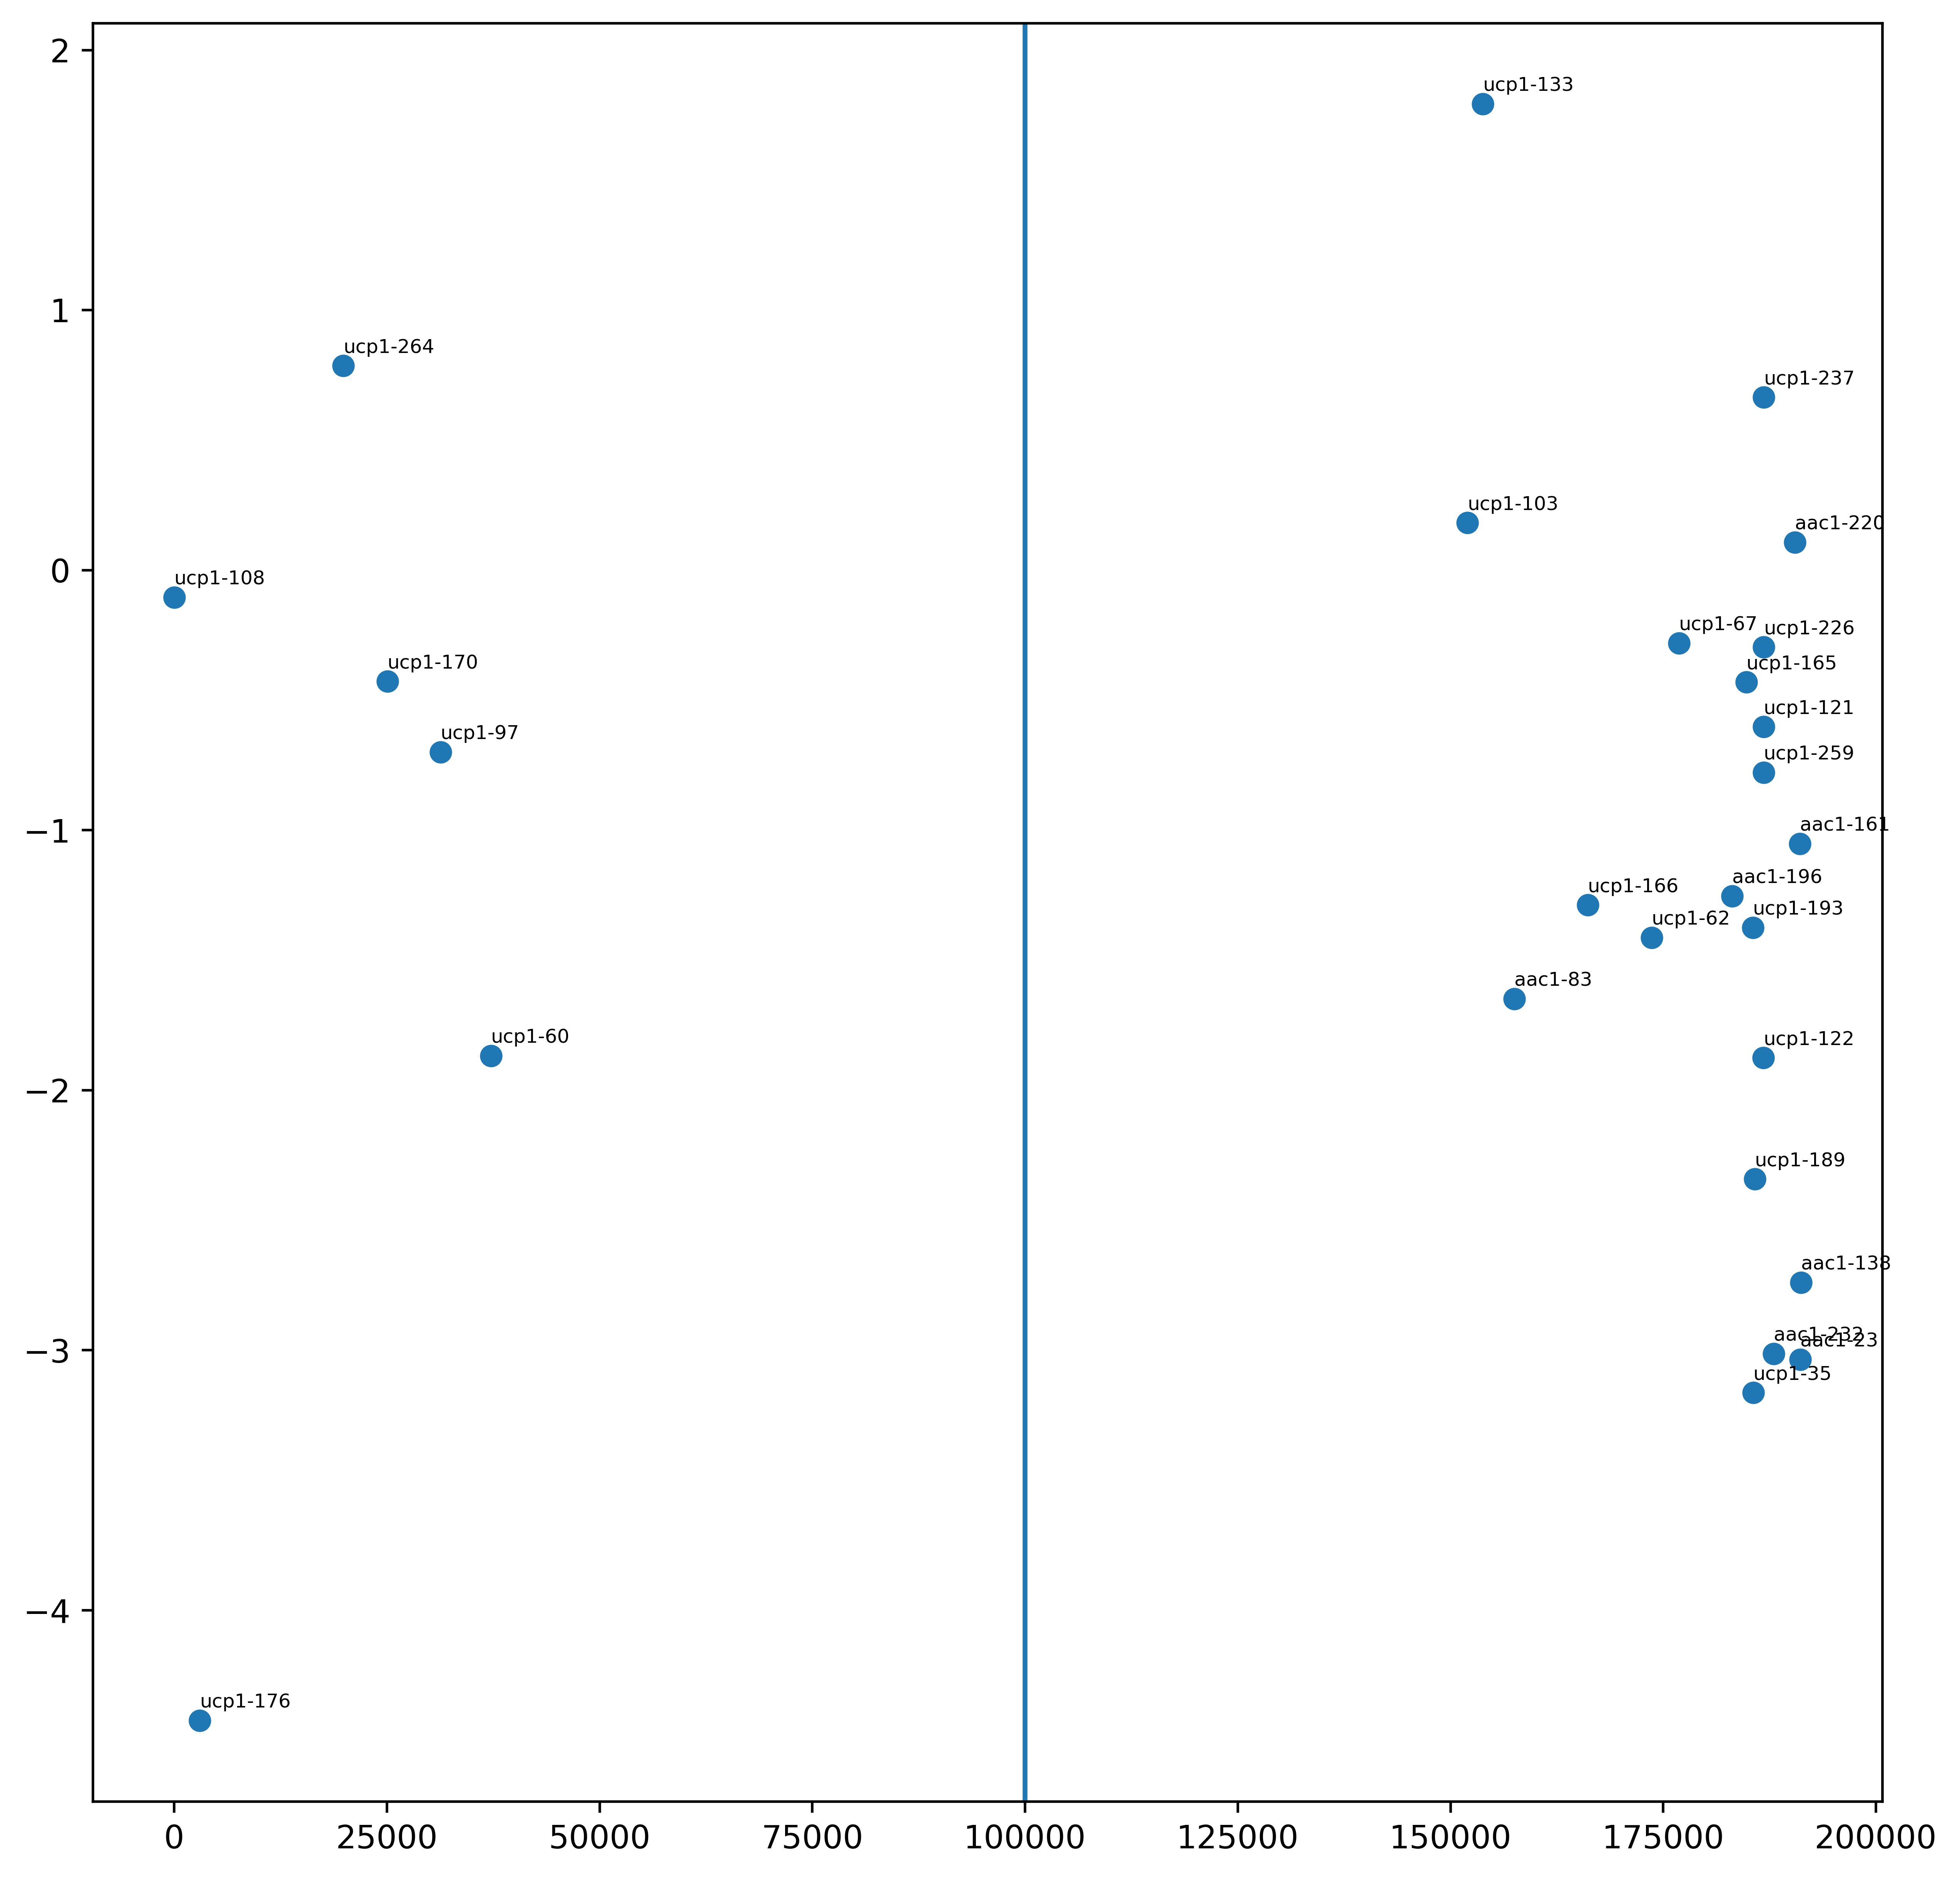

ucp1 helical resis:
35+62+67+103+121+122+133+165+166+189+193+226+237+259
aac1 helical resis:
23+83+138+161+196+220+232
single-protein 99.0% confidence interval: ConfidenceInterval(low=-1.8147711144289018, high=-0.49007118238111735)
---------------------------------------------: overall
data for 21 residues
each residue used below has at least 30.4057 microseconds of aggregate data in a helix
water H-bonding favors 180 degree rotamer by 1.14 kT on helices


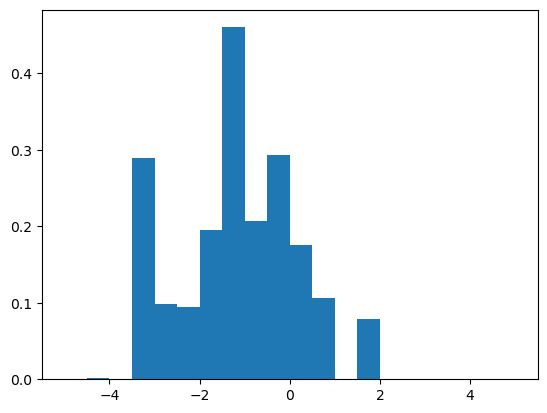

2-protein combined 95.0% t-test confidence interval: (-1.72695175302524, -0.5450750150917242)
2-protein combined 95.0% bootstrap confidence interval: (-1.6524305394751349, -0.6299627653529875)


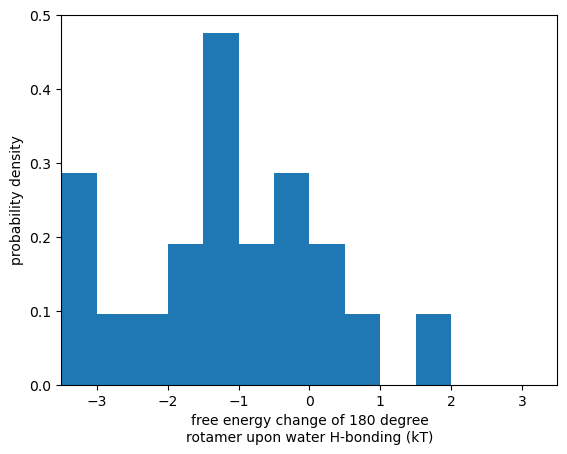

In [83]:
#hide everything; show cart; show sticks, poly and not elem H; util.cbag; util.cbam resn thr

resn = "thr"
ddG_all, weights_all, prot_all, resseq_all = load_process(heatmap_1, resn)
compile_results(ddG_all, weights_all, prot_all, resseq_all, resn)

In [59]:
####################################################################################
#                                 TRIMMINGS BELOW
####################################################################################